# Phase 1 - Exploratory Data Analysis
## Telecom Customer Churn

**Input:** UCI Machine Learning Repository dataset 563 (Iranian Churn) - 3,150 customers, 13 features
**Output:** the modelling decisions recorded below, before any pipeline is fitted in `train.py`

## What this notebook answers

A data scientist asks *"what does the data look like?"*. An architect asks *"what will this data do to
my model, and to the business depending on it?"*

Four questions are answered before modelling:

1. **Is the target meaningful?** What does `Churn` mean, and how is it distributed?
2. **Is the data internally consistent?** Business-logic checks, not just statistical ones.
3. **Which features plausibly drive churn?** Three, with evidence.
4. **What will class imbalance do?** An imbalanced target can collapse a model onto the majority class.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, recall_score
from ucimlrepo import fetch_ucirepo

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

In [2]:
dataset = fetch_ucirepo(id=563)

features = dataset.data.features
target = dataset.data.targets.iloc[:, 0]

print("Features:", features.shape)
print("Target:  ", target.name)

Features: (3150, 13)
Target:   Churn


In [3]:
dataset.variables[["name", "role", "type", "description"]]

,name,role,type,description
0,Call Failure,Feature,Integer,None
1,Complains,Feature,Binary,None
2,Subscription Length,Feature,Integer,None
3,Charge Amount,Feature,Integer,None
4,Seconds of Use,Feature,Integer,None
5,Frequency of use,Feature,Integer,None
6,Frequency of SMS,Feature,Integer,None
7,Distinct Called Numbers,Feature,Integer,None
8,Age Group,Feature,Integer,None
9,Tariff Plan,Feature,Integer,None


In [4]:
df = features.assign(Churn=target)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Call Failure,3150.0,7.63,7.26,0.0,1.00,6.00,12.00,36.00
Complains,3150.0,0.08,0.27,0.0,0.00,0.00,0.00,1.00
Subscription Length,3150.0,32.54,8.57,3.0,30.00,35.00,38.00,47.00
Charge Amount,3150.0,0.94,1.52,0.0,0.00,0.00,1.00,10.00
Seconds of Use,3150.0,4472.46,4197.91,0.0,1391.25,2990.00,6478.25,17090.00
Frequency of use,3150.0,69.46,57.41,0.0,27.00,54.00,95.00,255.00
Frequency of SMS,3150.0,73.17,112.24,0.0,6.00,21.00,87.00,522.00
Distinct Called Numbers,3150.0,23.51,17.22,0.0,10.00,21.00,34.00,97.00
Age Group,3150.0,2.83,0.89,1.0,2.00,3.00,3.00,5.00
Tariff Plan,3150.0,1.08,0.27,1.0,1.00,1.00,1.00,2.00


## Step 1 - Missing values

The first thing to check is what is missing and why. Not every null is a data error; some are business
logic. Here nothing is missing, so the median imputer in the training pipeline is insurance for future
data rather than a fix for this snapshot.

In [6]:
df.isna().sum().sort_values(ascending=False)

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

## Step 2 - Business logic validation

Three checks that the data makes business sense. Each should return zero violations.

- **Check A** - usage counters cannot be negative.
- **Check B** - coded columns must hold only their documented codes.
- **Check C** - `Age` must agree with the `Age Group` bucket it was derived from.

In [7]:
counters = [
    "Call  Failure",
    "Subscription  Length",
    "Seconds of Use",
    "Frequency of use",
    "Frequency of SMS",
    "Distinct Called Numbers",
    "Customer Value",
]
counters = [column for column in counters if column in df.columns]

negatives = (df[counters] < 0).sum()
print("Check A - negative values per counter:")
print(negatives)
print("\nTotal violations:", int(negatives.sum()))

Check A - negative values per counter:
Call  Failure              0
Subscription  Length       0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Customer Value             0
dtype: int64

Total violations: 0


In [8]:
expected_codes = {
    "Complains": {0, 1},
    "Tariff Plan": {1, 2},
    "Status": {1, 2},
    "Churn": {0, 1},
}

print("Check B - unexpected codes:")
for column, allowed in expected_codes.items():
    if column in df.columns:
        unexpected = set(df[column].unique()) - allowed
        print(f"  {column:<12} {sorted(unexpected) if unexpected else 'clean'}")

Check B - unexpected codes:
  Complains    clean
  Tariff Plan  clean
  Status       clean
  Churn        clean


In [9]:
print("Check C - Age range per Age Group:")
print(df.groupby("Age Group")["Age"].agg(["min", "max", "count"]))

inconsistent = df.groupby("Age Group")["Age"].nunique().gt(1).sum()
print("\nAge groups spanning more than one Age value:", int(inconsistent))

Check C - Age range per Age Group:
           min  max  count
Age Group                 
1           15   15    123
2           25   25   1037
3           30   30   1425
4           45   45    395
5           55   55    170

Age groups spanning more than one Age value: 0


## Step 3 - The target

`Churn` is recorded at the end of the observation window: **1** means the customer left the operator,
**0** means they stayed. It is the label a customer-service system will ask this API about, so the
cost of being wrong is asymmetric - see Step 9.

Target distribution:
Churn
Stayed (0)     2655
Churned (1)     495
Name: count, dtype: int64

As percentages:
Churn
Stayed (0)     84.3
Churned (1)    15.7
Name: proportion, dtype: float64


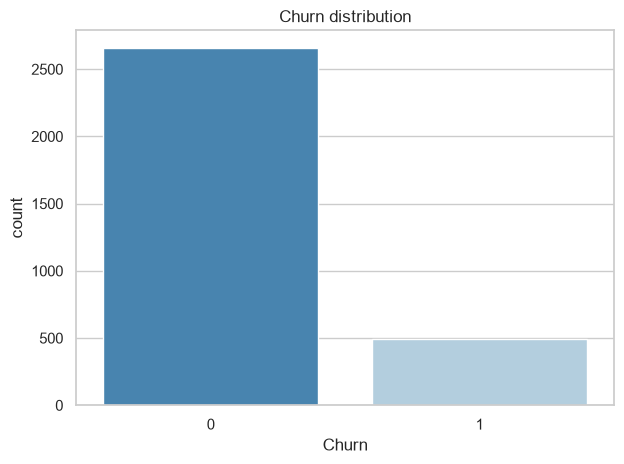

In [10]:
distribution = target.value_counts().rename({0: "Stayed (0)", 1: "Churned (1)"})
proportions = target.value_counts(normalize=True).mul(100).round(1)

print("Target distribution:")
print(distribution)
print("\nAs percentages:")
print(proportions.rename({0: "Stayed (0)", 1: "Churned (1)"}))

sns.countplot(x=target, palette="Blues_r", hue=target, legend=False)
plt.title("Churn distribution")
plt.xlabel("Churn")
plt.tight_layout()
plt.show()

## Step 4 - Distribution analysis

Every input column, split by how it behaves rather than by its dtype. Columns with few distinct values
are categorical in substance (flags and ordinal buckets) even though they arrive as integers.

In [11]:
CARDINALITY_LIMIT = 12

low_cardinality = [c for c in features.columns if features[c].nunique() <= CARDINALITY_LIMIT]
continuous = [c for c in features.columns if c not in low_cardinality]

print("Categorical in substance:", low_cardinality)
print("Continuous:              ", continuous)

Categorical in substance: ['Complains', 'Charge  Amount', 'Age Group', 'Tariff Plan', 'Status', 'Age']
Continuous:               ['Call  Failure', 'Subscription  Length', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Customer Value']


In [12]:
for column in low_cardinality:
    print(f"======= {column} =======")
    print(df[column].value_counts().sort_index())
    print()

======= Complains =======
Complains
0    2909
1     241
Name: count, dtype: int64

======= Charge  Amount =======
Charge  Amount
0     1768
1      617
2      395
3      199
4       76
5       30
6       11
7       14
8       19
9       14
10       7
Name: count, dtype: int64

======= Age Group =======
Age Group
1     123
2    1037
3    1425
4     395
5     170
Name: count, dtype: int64

======= Tariff Plan =======
Tariff Plan
1    2905
2     245
Name: count, dtype: int64

======= Status =======
Status
1    2368
2     782
Name: count, dtype: int64

======= Age =======
Age
15     123
25    1037
30    1425
45     395
55     170
Name: count, dtype: int64



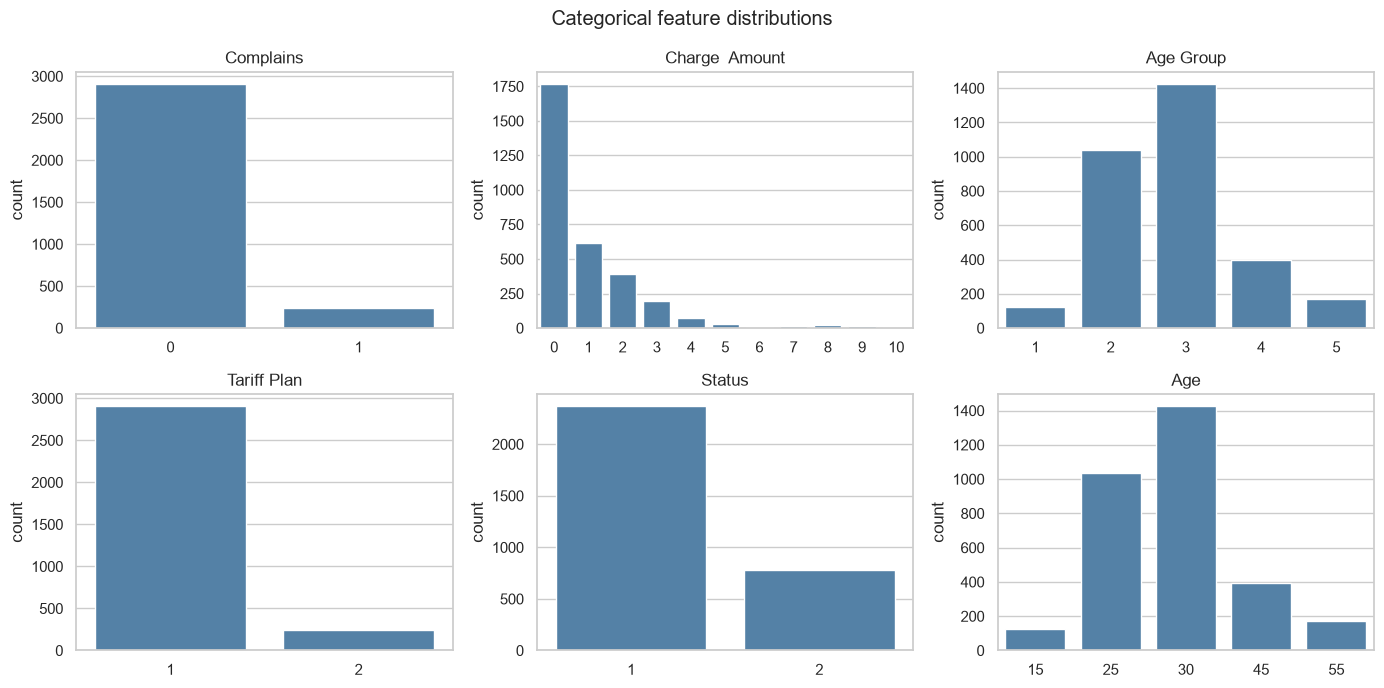

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for axis, column in zip(axes.flat, low_cardinality, strict=False):
    sns.countplot(data=df, x=column, ax=axis, color="steelblue")
    axis.set_title(column)
    axis.set_xlabel("")

for axis in axes.flat[len(low_cardinality) :]:
    axis.remove()

fig.suptitle("Categorical feature distributions")
fig.tight_layout()
plt.show()

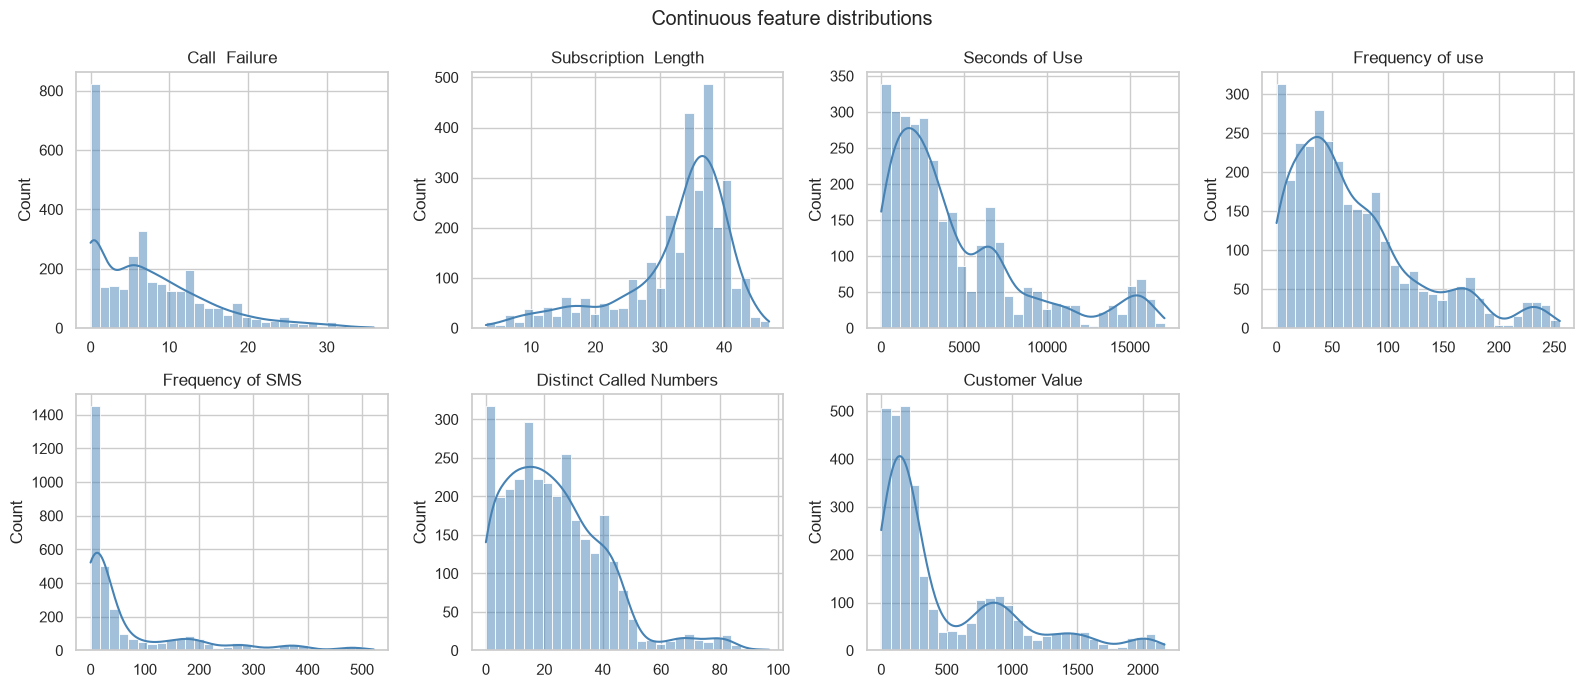

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for axis, column in zip(axes.flat, continuous, strict=False):
    sns.histplot(df[column], bins=30, kde=True, color="steelblue", ax=axis)
    axis.set_title(column)
    axis.set_xlabel("")

for axis in axes.flat[len(continuous) :]:
    axis.remove()

fig.suptitle("Continuous feature distributions")
fig.tight_layout()
plt.show()

In [15]:
df[continuous].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Call Failure,3150.0,7.63,7.26,0.0,1.00,6.00,12.00,36.00
Subscription Length,3150.0,32.54,8.57,3.0,30.00,35.00,38.00,47.00
Seconds of Use,3150.0,4472.46,4197.91,0.0,1391.25,2990.00,6478.25,17090.00
Frequency of use,3150.0,69.46,57.41,0.0,27.00,54.00,95.00,255.00
Frequency of SMS,3150.0,73.17,112.24,0.0,6.00,21.00,87.00,522.00
Distinct Called Numbers,3150.0,23.51,17.22,0.0,10.00,21.00,34.00,97.00
Customer Value,3150.0,470.97,517.02,0.0,113.80,228.48,788.39,2165.28


## Step 5 - Outliers

The interquartile range is the spread of the middle 50% of the data. A value beyond
`Q3 + 1.5 x IQR` sits outside the upper fence and is conventionally treated as an outlier.

These are heavy-tailed usage counters, not data errors: a handful of very high-usage customers is
exactly what a telecom dataset should contain. They are kept, and the `StandardScaler` in the training
pipeline keeps their scale from dominating the coefficients.

In [16]:
quartiles = df[continuous].quantile([0.25, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]
upper_fence = quartiles.loc[0.75] + 1.5 * iqr

outlier_summary = pd.DataFrame(
    {
        "q1": quartiles.loc[0.25].round(2),
        "q3": quartiles.loc[0.75].round(2),
        "iqr": iqr.round(2),
        "upper_fence": upper_fence.round(2),
        "above_fence": (df[continuous] > upper_fence).sum(),
    }
)
outlier_summary["above_fence_pct"] = outlier_summary["above_fence"].div(len(df)).mul(100).round(2)
outlier_summary

,q1,q3,iqr,upper_fence,above_fence,above_fence_pct
Call Failure,1.00,12.00,11.00,28.50,47,1.49
Subscription Length,30.00,38.00,8.00,50.00,0,0.00
Seconds of Use,1391.25,6478.25,5087.00,14108.75,200,6.35
Frequency of use,27.00,95.00,68.00,197.00,129,4.10
Frequency of SMS,6.00,87.00,81.00,208.50,368,11.68
Distinct Called Numbers,10.00,34.00,24.00,70.00,77,2.44
Customer Value,113.80,788.39,674.59,1800.27,116,3.68


## Step 6 - Feature correlations

Correlation with `Churn` is a first filter, not a verdict: it only measures the linear part of each
relationship. It is still the right lens here, because the model being trained is linear.

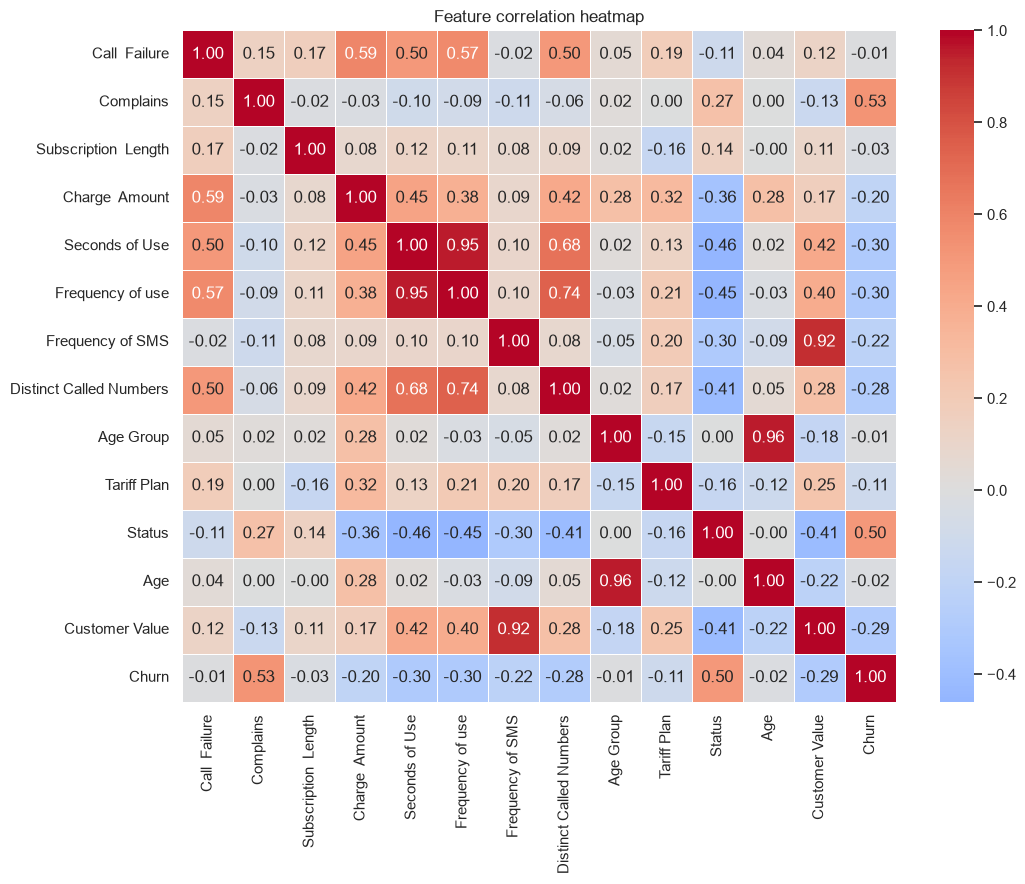

In [17]:
correlation = df.corr(numeric_only=True).round(2)

plt.figure(figsize=(11, 9))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidth=0.5)
plt.title("Feature correlation heatmap")
plt.tight_layout()
plt.show()

In [18]:
churn_correlation = correlation["Churn"].drop("Churn").sort_values(ascending=False)

print("Correlation with Churn (sorted):")
print(churn_correlation)

Correlation with Churn (sorted):
Complains                  0.53
Status                     0.50
Call  Failure             -0.01
Age Group                 -0.01
Age                       -0.02
Subscription  Length      -0.03
Tariff Plan               -0.11
Charge  Amount            -0.20
Frequency of SMS          -0.22
Distinct Called Numbers   -0.28
Customer Value            -0.29
Seconds of Use            -0.30
Frequency of use          -0.30
Name: Churn, dtype: float64


## Step 7 - Three features that could plausibly influence churn

Picked for a causal story a telecom analyst would recognise, then checked against the data.

| Feature | Why it could drive churn |
|---|---|
| `Status` | Whether the line is already non-active - disengagement usually precedes leaving. |
| `Complains` | A logged complaint is a customer who has already told the operator something is wrong. |
| `Seconds of Use` | Low usage means the service has stopped being part of the customer's routine. |

In [19]:
for column in ["Status", "Complains"]:
    churn_rate = df.groupby(column)["Churn"].mean().mul(100).round(1)
    print(f"Churn rate by {column} (%):")
    print(churn_rate)
    print()

Churn rate by Status (%):
Status
1     5.3
2    47.3
Name: Churn, dtype: float64

Churn rate by Complains (%):
Complains
0    10.1
1    83.0
Name: Churn, dtype: float64



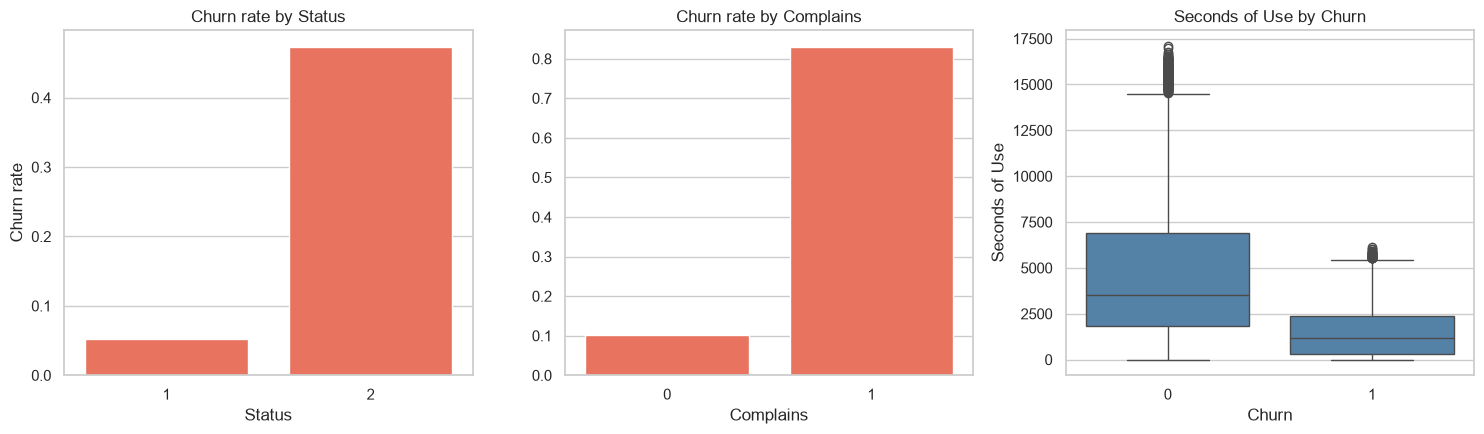

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.barplot(data=df, x="Status", y="Churn", ax=axes[0], color="tomato", errorbar=None)
axes[0].set_title("Churn rate by Status")
axes[0].set_ylabel("Churn rate")

sns.barplot(data=df, x="Complains", y="Churn", ax=axes[1], color="tomato", errorbar=None)
axes[1].set_title("Churn rate by Complains")
axes[1].set_ylabel("")

sns.boxplot(data=df, x="Churn", y="Seconds of Use", ax=axes[2], color="steelblue")
axes[2].set_title("Seconds of Use by Churn")

fig.tight_layout()
plt.show()

In [21]:
usage_by_churn = df.groupby("Churn")[["Seconds of Use", "Frequency of use", "Customer Value"]]
print("Mean usage by churn outcome:")
print(usage_by_churn.mean().round(1))

Mean usage by churn outcome:
       Seconds of Use  Frequency of use  Customer Value
Churn                                                  
0              5014.2              77.0           535.5
1              1566.6              29.1           124.8


## Step 8 - Class imbalance and class collapse

**Class imbalance** means one class holds far more rows than the other. **Class collapse** is what a
model does about it: predict the majority class almost always, score a respectable accuracy, and
never find a churner.

The demonstration below uses the three features from Step 7 only, so the effect of
`class_weight="balanced"` is visible rather than buried under a full feature set.

In [22]:
majority_class = int(target.mode()[0])
naive_accuracy = (target == majority_class).mean()

print(f"Majority class: {majority_class}")
print(f"Accuracy of always predicting it: {naive_accuracy:.1%}")

Majority class: 0
Accuracy of always predicting it: 84.3%


In [23]:
demo_columns = ["Status", "Complains", "Seconds of Use"]
demo_features = df[demo_columns]
demo_target = df["Churn"]

unweighted = LogisticRegression(max_iter=1000, random_state=42)
unweighted.fit(demo_features, demo_target)
unweighted_predictions = unweighted.predict(demo_features)

print('Without class_weight="balanced":')
print("-" * 55)
print(classification_report(demo_target, unweighted_predictions, zero_division=0))

Without class_weight="balanced":
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      2655
           1       0.91      0.38      0.54       495

    accuracy                           0.90      3150
   macro avg       0.90      0.69      0.74      3150
weighted avg       0.90      0.90      0.88      3150



In [24]:
weighted = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
weighted.fit(demo_features, demo_target)
weighted_predictions = weighted.predict(demo_features)

print('With class_weight="balanced":')
print("-" * 55)
print(classification_report(demo_target, weighted_predictions, zero_division=0))

With class_weight="balanced":
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.97      0.84      0.90      2655
           1       0.50      0.87      0.64       495

    accuracy                           0.84      3150
   macro avg       0.74      0.85      0.77      3150
weighted avg       0.90      0.84      0.86      3150



In [25]:
unweighted_recall = recall_score(demo_target, unweighted_predictions, pos_label=1)
weighted_recall = recall_score(demo_target, weighted_predictions, pos_label=1)

print("CHURN RECALL - the share of real churners the model finds")
print("-" * 55)
print(f"Without class_weight : {unweighted_recall:.0%}")
print(f"With class_weight    : {weighted_recall:.0%}")

CHURN RECALL - the share of real churners the model finds
-------------------------------------------------------
Without class_weight : 38%
With class_weight    : 87%


## Step 9 - What a false negative means to the business

A **false negative** is a customer the model clears as safe who then leaves. Nobody calls them, no
retention offer is made, and the operator loses the contract plus the cost of winning a replacement -
which in telecom is several times the cost of the discount that would have kept them.

A **false positive** is a retention offer sent to a customer who was staying anyway: a margin cost on
one account, recoverable next month.

The two errors are not symmetric, so churn **recall** is the metric this project is judged on, and
accuracy alone would be a misleading headline on a target this imbalanced.

### Decisions carried into `train.py`

- `class_weight="balanced"` on the Logistic Regression - the imbalance above makes it mandatory.
- `stratify=y` on the train/test split, so the test set keeps the real churn rate.
- `StandardScaler`, because the usage counters are heavy-tailed and on wildly different scales.
- `SimpleImputer(strategy="median")` - redundant on this snapshot, insurance on future data.
- Report precision, recall, F1 for the churn class and ROC-AUC. Never accuracy on its own.
- Persist the whole fitted pipeline, so serving cannot drift from training.